
Loaded model fitting results:

 Noise_arcmin               Model  RMSE_AU
            1  Free-center circle 0.021718
            1      Kepler ellipse 0.021759
            1 Sun-centered circle 0.051504
            2  Free-center circle 0.021879
            2      Kepler ellipse 0.021920
            2 Sun-centered circle 0.051629
            5  Free-center circle 0.022431
            5      Kepler ellipse 0.022475
            5 Sun-centered circle 0.052027


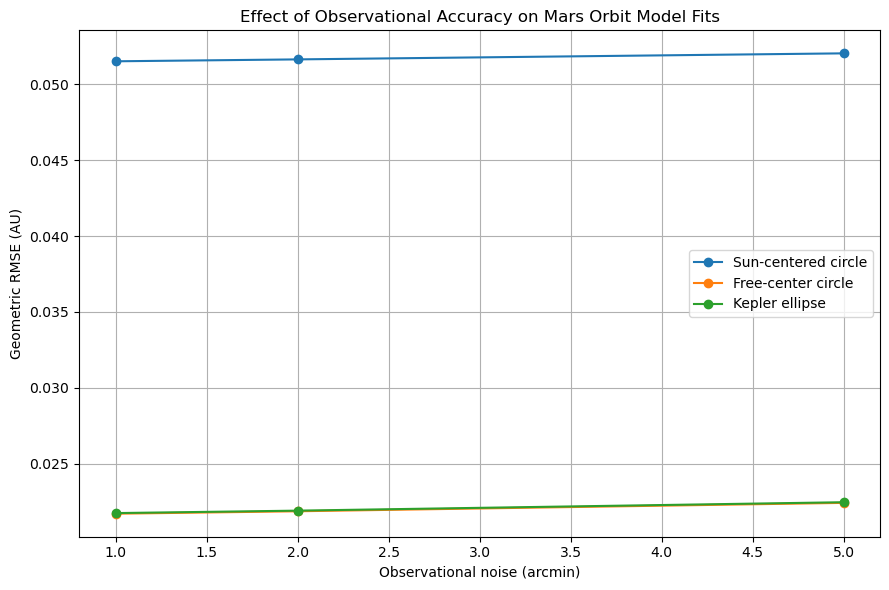


STEP 7 NOISE COMPARISON

 Noise_arcmin  Sun_circle_RMSE  Free_circle_RMSE  Ellipse_RMSE  Ellipse_minus_Free_RMSE  Ellipse_vs_Free_percent  Ellipse_improvement_vs_Sun_percent
            1         0.051504          0.021718      0.021759                 0.000041                 0.187891                           57.752343
            2         0.051629          0.021879      0.021920                 0.000041                 0.188044                           57.543733
            5         0.052027          0.022431      0.022475                 0.000043                 0.193293                           56.802071

Interpretation:

1 arcmin: free-center circle has slightly lower RMSE.
2 arcmin: free-center circle has slightly lower RMSE.
5 arcmin: free-center circle has slightly lower RMSE.

Saved:
  step7_noise_vs_rmse.png
  step7_noise_comparison.csv


In [1]:
"""
step7_noise_comparison.py

Homework 1.1 - Step 7

Compare model-fitting errors for:

    1 arcmin
    2 arcmin
    5 arcmin

using the Step 6 output:

    model_fit_summary.csv

Goal:
Determine whether increasing observational accuracy makes
the ellipse clearly outperform the circular models.
"""

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD STEP 6 RESULTS
# ============================================================

df = pd.read_csv(
    "model_fit_summary.csv"
)

print("\nLoaded model fitting results:\n")

print(
    df[
        [
            "Noise_arcmin",
            "Model",
            "RMSE_AU"
        ]
    ].to_string(index=False)
)


# ============================================================
# 2. EXTRACT EACH MODEL
# ============================================================

sun_circle = (
    df[
        df["Model"]
        ==
        "Sun-centered circle"
    ]
    .sort_values("Noise_arcmin")
)

free_circle = (
    df[
        df["Model"]
        ==
        "Free-center circle"
    ]
    .sort_values("Noise_arcmin")
)

ellipse = (
    df[
        df["Model"]
        ==
        "Kepler ellipse"
    ]
    .sort_values("Noise_arcmin")
)


# ============================================================
# 3. PLOT RMSE VERSUS OBSERVATIONAL NOISE
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    sun_circle["Noise_arcmin"],
    sun_circle["RMSE_AU"],
    marker="o",
    label="Sun-centered circle"
)

plt.plot(
    free_circle["Noise_arcmin"],
    free_circle["RMSE_AU"],
    marker="o",
    label="Free-center circle"
)

plt.plot(
    ellipse["Noise_arcmin"],
    ellipse["RMSE_AU"],
    marker="o",
    label="Kepler ellipse"
)

plt.xlabel(
    "Observational noise (arcmin)"
)

plt.ylabel(
    "Geometric RMSE (AU)"
)

plt.title(
    "Effect of Observational Accuracy "
    "on Mars Orbit Model Fits"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    "step7_noise_vs_rmse.png",
    dpi=300
)

plt.show()


# ============================================================
# 4. COMPARE ELLIPSE AGAINST FREE-CENTER CIRCLE
# ============================================================

comparison_rows = []

for noise in [1, 2, 5]:

    free_rmse = float(
        free_circle[
            free_circle["Noise_arcmin"] == noise
        ]["RMSE_AU"].iloc[0]
    )

    ellipse_rmse = float(
        ellipse[
            ellipse["Noise_arcmin"] == noise
        ]["RMSE_AU"].iloc[0]
    )

    sun_rmse = float(
        sun_circle[
            sun_circle["Noise_arcmin"] == noise
        ]["RMSE_AU"].iloc[0]
    )

    # Positive value means ellipse is worse
    # than the free-center circle.
    ellipse_minus_free = (
        ellipse_rmse
        -
        free_rmse
    )

    relative_difference_percent = (
        ellipse_minus_free
        /
        free_rmse
        * 100
    )

    # How much better is the ellipse than the
    # Sun-centered circle?
    improvement_vs_sun_percent = (
        (
            sun_rmse
            -
            ellipse_rmse
        )
        /
        sun_rmse
        * 100
    )

    comparison_rows.append({
        "Noise_arcmin":
            noise,

        "Sun_circle_RMSE":
            sun_rmse,

        "Free_circle_RMSE":
            free_rmse,

        "Ellipse_RMSE":
            ellipse_rmse,

        "Ellipse_minus_Free_RMSE":
            ellipse_minus_free,

        "Ellipse_vs_Free_percent":
            relative_difference_percent,

        "Ellipse_improvement_vs_Sun_percent":
            improvement_vs_sun_percent
    })


comparison = pd.DataFrame(
    comparison_rows
)


# ============================================================
# 5. PRINT COMPARISON
# ============================================================

print(
    "\n========================================"
)

print(
    "STEP 7 NOISE COMPARISON"
)

print(
    "========================================\n"
)

print(
    comparison.to_string(
        index=False
    )
)


# ============================================================
# 6. DETERMINE WHETHER ELLIPSE WINS
# ============================================================

print(
    "\nInterpretation:\n"
)

for _, row in comparison.iterrows():

    noise = row["Noise_arcmin"]

    free_rmse = row[
        "Free_circle_RMSE"
    ]

    ellipse_rmse = row[
        "Ellipse_RMSE"
    ]

    if ellipse_rmse < free_rmse:

        print(
            f"{noise:.0f} arcmin: "
            "ellipse has lower RMSE."
        )

    else:

        print(
            f"{noise:.0f} arcmin: "
            "free-center circle has slightly "
            "lower RMSE."
        )


# ============================================================
# 7. SAVE TABLE
# ============================================================

comparison.to_csv(
    "step7_noise_comparison.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "  step7_noise_vs_rmse.png"
)

print(
    "  step7_noise_comparison.csv"
)

Across observational noise levels of \(1'\), \(2'\), and \(5'\), the Sun-centered circular model consistently produced substantially larger residual errors than either the shifted circle or the Kepler ellipse. The ellipse improved the fit relative to the Sun-centered circle by approximately \(57\%\), demonstrating that a simple Sun-centered circular orbit is inconsistent with the reconstructed data. However, the arbitrary-center circle and ellipse had nearly identical errors, with the free-center circle having an RMSE lower by only about \(0.19\%\) at each noise level. Therefore, within the present experiment, even one-arcminute observational accuracy was not sufficient for the ellipse to clearly outperform a shifted circle. The small change in fit quality between \(1'\) and \(5'\) suggests that reconstruction error and incomplete orbital coverage are more important limitations than observational noise itself.